# Proyecto Melbourne Housing · Random Forest

**Random Forest** (S06): muchos árboles de decisión entrenados con muestras aleatorias; la predicción es la media de todos.

In [1]:
# Imports & configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from pathlib import Path
import folium
from folium.plugins import MarkerCluster
import subprocess, sys
from IPython.display import IFrame


sns.set_theme(style="whitegrid")

In [2]:
# Define path for the new melbourne csv
BASE = Path.cwd().parent
CLEAN_FILE = BASE / "datasets" / "melbourne_limpio.csv"
# Create dataframe from csv
df = pd.read_csv(CLEAN_FILE)

# drop_first=True drops one category per column to avoid multicollinearity and encode to 0/1 the categorical values
df_modelo = pd.get_dummies(df, columns=["Type", "Suburb", "Method", "SellerG"], drop_first=True)
print(str(df_modelo.shape[0]) + "  " + str(df_modelo.shape[1]))
#print(df_modelo.head(4))
# Split the data into features (X) and target variable (y, the price)
X = df_modelo.drop("Price", axis=1)
y = df_modelo["Price"]
# Split into training (80%) and test (20 0/0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"{len(df)} viviendas | {df.shape[1]} columnas")

27246  708
27246 viviendas | 15 columnas


## 2. Elegir la profundidad (curva de error, como en S05)

Si el error de prueba deja de bajar mientras el de entrenamiento sigue bajando, hay sobreajuste.

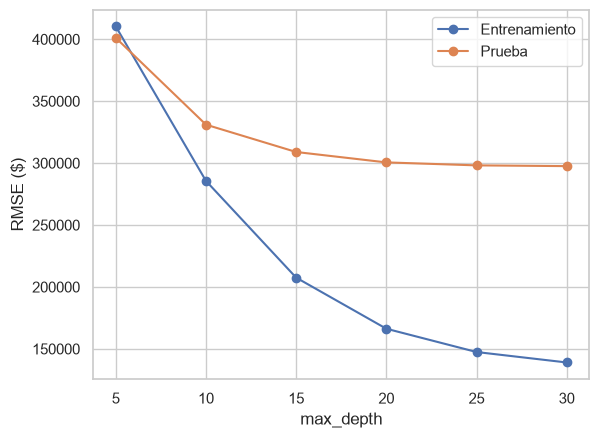

Mejor profundidad: 30


In [3]:
# List of max_depth values to evaluate for the random forest
profundidades = [5, 10, 15, 20, 25, 30]
# Store the RMSE on the training and test sets for each depth
rmse_train, rmse_test = [], []

for d in profundidades:
    # Train a random forest with 100 trees and the current max_depth.
    # n_jobs=-1 uses all available CPU cores; random_state=42 keeps results reproducible.
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1).fit(X_train, y_train)
    # RMSE on the training set (square root of the mean squared error)
    rmse_train.append(np.sqrt(mean_squared_error(y_train, rf.predict(X_train))))
    # RMSE on the test set, to measure how well the model generalizes
    rmse_test.append(np.sqrt(mean_squared_error(y_test, rf.predict(X_test))))

# Plot both curves: training error and test error as a function of max_depth
plt.plot(profundidades, rmse_train, "o-", label="Entrenamiento")  # "Entrenamiento" = Training
plt.plot(profundidades, rmse_test, "o-", label="Prueba")          # "Prueba" = Test
plt.xlabel("max_depth")
plt.ylabel("RMSE ($)")
plt.legend()
plt.show()

# Pick the depth with the lowest test RMSE (best generalization)
mejor_profundidad = profundidades[np.argmin(rmse_test)]
# Print the best depth found
print(f"Mejor profundidad: {mejor_profundidad}")  # "Mejor profundidad" = Best depth

## 3. Modelo final y validación cruzada (5 folds)

In [4]:
# Final model: 300 trees, using the best max_depth found in the search above
modelo_rf = RandomForestRegressor(n_estimators=300, max_depth=mejor_profundidad, random_state=42, n_jobs=-1)
# Train on the training split only, so the test split stays unseen
modelo_rf.fit(X_train, y_train)
# Predict prices for the held-out test set
pred_test = modelo_rf.predict(X_test)

# RMSE in dollars: typical size of the prediction error, penalizing large errors more
print(f"RMSE prueba: {np.sqrt(mean_squared_error(y_test, pred_test)):,.0f} $")  # "prueba" = test
# MAE in dollars: average absolute error, easier to interpret than RMSE
print(f"MAE prueba:  {mean_absolute_error(y_test, pred_test):,.0f} $")
# R²: share of price variance explained by the model (1.0 is perfect, 0 is no better than the mean)
print(f"R² prueba:   {r2_score(y_test, pred_test):.3f}")

# Cross-validation: train and evaluate 5 times, each time holding out a different fifth of the data
# Uses the full X and y, not the single train/test split, to get a more stable estimate
r2_cv = cross_val_score(
    RandomForestRegressor(n_estimators=100, max_depth=mejor_profundidad, random_state=42, n_jobs=-1),
    X, y, cv=5, scoring="r2"
)
# R² for each fold, then the mean across folds ("en los 5 folds" = across the 5 folds)
print(f"R² en los 5 folds: {np.round(r2_cv, 3)} -> media {r2_cv.mean():.3f}")

RMSE prueba: 295,634 $
MAE prueba:  181,026 $
R² prueba:   0.778
R² en los 5 folds: [0.722 0.686 0.724 0.714 0.734] -> media 0.716


## 1.1 · Predice el precio medio de una vivienda

Precio medio real:     1,046,728 $
Precio medio predicho: 1,040,336 $


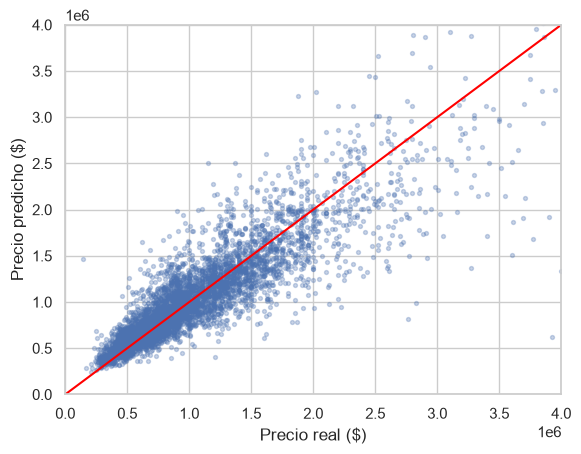

In [5]:
# Compare the average real price with the average predicted price on the test set
print(f"Precio medio real:     {y_test.mean():,.0f} $")      # "Precio medio real" = Real average price
print(f"Precio medio predicho: {pred_test.mean():,.0f} $")   # "Precio medio predicho" = Predicted average price

# Scatter plot of real vs predicted prices for each test house
# alpha=0.3 makes overlapping points visible; s=8 sets a small marker size
plt.scatter(y_test, pred_test, alpha=0.3, s=8)
# Red diagonal y = x: points on this line would be perfect predictions
plt.plot([0, 4e6], [0, 4e6], color="red")
# Fix both axes to the same range (0 to 4 million dollars) so the diagonal is comparable
plt.xlim(0, 4e6)
plt.ylim(0, 4e6)
plt.xlabel("Precio real ($)")      # "Precio real" = Real price
plt.ylabel("Precio predicho ($)")  # "Precio predicho" = Predicted price
plt.show()

## 1.2 · ¿Qué características encarecen una vivienda?

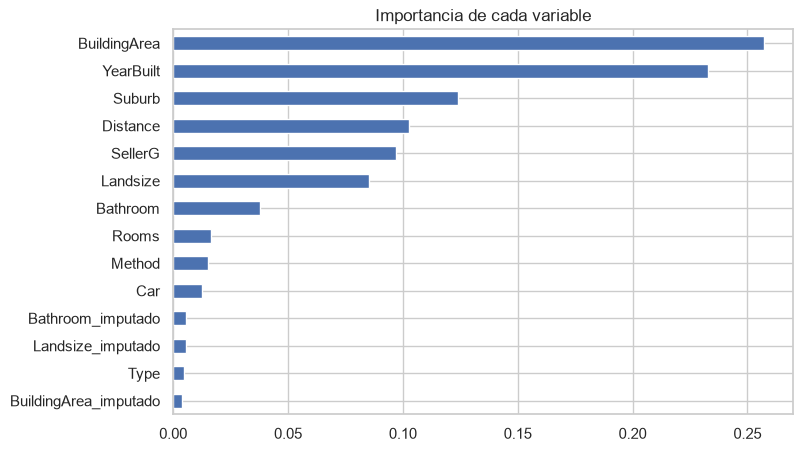

BuildingArea    0.54
Distance       -0.19
YearBuilt      -0.43
Landsize        0.05
Rooms           0.50
Price           1.00
Name: Price, dtype: float64

In [6]:
# Feature importances from the fitted random forest, one value per column of X
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns)

# One-hot encoding created columns like "Suburb_Abbotsford". Strip the suffix so each
# categorical variable is identified by its original name ("Suburb").
importancias.index = [c.split("_")[0] if c.split("_")[0] in ["Type", "Suburb", "Method", "SellerG"] else c
                      for c in importancias.index]

# Add up the importances of all dummy columns that came from the same variable,
# then sort from least to most important for the horizontal bar chart
importancias = importancias.groupby(level=0).sum().sort_values()

# Horizontal bar chart of the total importance of each original variable
importancias.plot(kind="barh", figsize=(8, 5), title="Importancia de cada variable")  # "Importancia de cada variable" = Importance of each variable
plt.show()

# Does the price go up or down with each numeric variable?
# Spearman correlation with Price: values near +1 mean the price rises with the variable,
# near -1 mean it falls, and near 0 mean there is no monotonic relationship.
df[["BuildingArea", "Distance", "YearBuilt", "Landsize", "Rooms", "Price"]].corr(method="spearman")["Price"].round(2)

## 1.3 · ¿Qué tipo de vivienda genera más beneficio?

In [7]:
# Copy the test-set rows from the original DataFrame, keeping their original index
prueba = df.loc[X_test.index].copy()
# Predicted price per square meter: model prediction divided by building area
prueba["precio_m2"] = pred_test / prueba["BuildingArea"]
# Keep only houses whose building area was not imputed and is at least 20 m²,
# since tiny or estimated areas make the price per m² unreliable
prueba = prueba[(prueba["BuildingArea_imputado"] == 0) & (prueba["BuildingArea"] >= 20)]

# Median of each metric per property type (h = house, t = townhouse, u = unit)
prueba.groupby("Type")[["precio_m2", "Price", "BuildingArea", "Landsize", "Distance"]].median().round(0)

,precio_m2,Price,BuildingArea,Landsize,Distance
Type,,,,,
h,7333.0,1020000.0,150.0,574.0,11.0
t,6408.0,840000.0,134.0,211.0,10.0
u,7683.0,550000.0,76.0,601.0,6.0


## 1.4 · ¿Es rentable un terreno sin construir?

In [ ]:
from sklearn.model_selection import KFold

COSTE_M2 = 2_000
OTROS_COSTES = 0.15
SENSIBILIDAD = [1_500, 2_000, 2_500, 3_000, 3_500]
EXCLUIR = ["Price", "Type", "Address", "Lat", "Lon"]
cat_14 = ["Suburb", "Method", "SellerG"]

# 1. Solo casas con superficie construida real
casas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 0)].copy()
columnas_rf = list(pd.get_dummies(casas.drop(columns=EXCLUIR, errors="ignore"),
                                  columns=cat_14, dtype=int).columns)

def matriz_rf(datos):
    d = pd.get_dummies(datos.drop(columns=EXCLUIR, errors="ignore"), columns=cat_14, dtype=int)
    return d.reindex(columns=columnas_rf, fill_value=0)

X_rf, y_rf = matriz_rf(casas), casas["Price"]

print("=" * 52)
print("RANDOM FOREST · SOLO CASAS")
print("=" * 52)
print(f"Casas con superficie real : {len(casas):,}")
print(f"Variables del modelo      : {X_rf.shape[1]:,}")
print(f"Profundidad máxima        : {mejor_profundidad}")
print()

# 2. Validación cruzada (5 folds)
rf_14 = RandomForestRegressor(n_estimators=100, max_depth=mejor_profundidad,
                              min_samples_leaf=2, random_state=42, n_jobs=-1)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_14 = cross_val_score(rf_14, X_rf, y_rf, cv=kf, scoring="r2")
rmse_14 = -cross_val_score(rf_14, X_rf, y_rf, cv=kf, scoring="neg_root_mean_squared_error")

print("VALIDACIÓN CRUZADA (5 folds)")
print("-" * 52)
for i, (r2, rmse) in enumerate(zip(r2_14, rmse_14), start=1):
    print(f"Fold {i}  ·  R² = {r2:.3f}  ·  RMSE = {rmse:>10,.0f} $")
print("-" * 52)
print(f"Media    ·  R² = {r2_14.mean():.3f}  ·  RMSE = {rmse_14.mean():>10,.0f} $")
print(f"Desv.    ·  R² = {r2_14.std():.3f}  ·  RMSE = {rmse_14.std():>10,.0f} $")
print()

# 3. Modelo final
modelo_14 = RandomForestRegressor(n_estimators=300, max_depth=mejor_profundidad,
                                  min_samples_leaf=2, random_state=42, n_jobs=-1)
modelo_14.fit(X_rf, y_rf)
print("Modelo final entrenado con todas las casas.")

Casas con superficie construida real: 7889
R² por fold: [0.745 0.735 0.741 0.752 0.678] -> media 0.730
RMSE medio: 369,097 $ (± 19,047)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",30
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

### Parcelas, margenes y sensibilidad

In [9]:
# 4. Parcelas: casas con parcela >= 200 m² y superficie construida imputada
parcelas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 1) &
              (df["Landsize_imputado"] == 0) & (df["Landsize"] >= 200)].copy()

# Casa nueva: la mitad de la parcela, máximo 200 m², año 2026
m2_nuevos = np.minimum(parcelas["Landsize"] * 0.5, 200)
nueva = parcelas.assign(BuildingArea=m2_nuevos, YearBuilt=2026, BuildingArea_imputado=0)
valor = modelo_14.predict(matriz_rf(nueva))

# 5. Margen para un coste de obra dado
def margen(coste_m2):
    coste_total = parcelas["Price"] + m2_nuevos * coste_m2 * (1 + OTROS_COSTES)
    return (valor - coste_total) / coste_total * 100

parcelas["margen_pct"] = margen(COSTE_M2)
print(f"{len(parcelas)} parcelas | margen mediano {parcelas['margen_pct'].median():.1f} % "
      f"| rentables (>15 %): {(parcelas['margen_pct'] > 15).mean() * 100:.1f} %")

# 6. Sensibilidad: qué pasa si la obra cuesta más o menos
sensibilidad = pd.DataFrame({
    "Coste obra (AUD/m²)": SENSIBILIDAD,
    "Margen mediano (%)": [margen(c).median() for c in SENSIBILIDAD],
    "% parcelas > 15 %": [(margen(c) > 15).mean() * 100 for c in SENSIBILIDAD],
}).round(1)
sensibilidad

6009 parcelas | margen mediano -27.5 % | rentables (>15 %): 1.2 %


,Coste obra (AUD/m²),Margen mediano (%),% parcelas > 15 %
0,1500,-21.5,3.1
1,2000,-27.5,1.2
2,2500,-32.4,0.5
3,3000,-36.7,0.3
4,3500,-40.3,0.2


In [10]:
## Margen por suburbio

# 7. Margen mediano por suburbio (solo suburbios con al menos 5 parcelas)
por_suburbio = parcelas.groupby("Suburb")["margen_pct"].agg(["count", "median"])
por_suburbio[por_suburbio["count"] >= 5].sort_values("median", ascending=False).round(1).iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]]

,count,median
Suburb,,
Brooklyn,5,14.2
Dallas,6,5.6
Heidelberg West,46,1.1
Abbotsford,5,0.4
Spotswood,12,-2.9
Eaglemont,8,-49.7
Canterbury,19,-49.9
Burwood East,16,-50.2
Malvern,21,-50.5


## Mapa

Viviendas de prueba sobre el mapa de Melbourne: 🟢 más de un 10 % por debajo de la predicción, 🔵 ±10 %, 🔴 más de un 10 % por encima. Clic en un punto para ver sus datos.

In [11]:

# Path to the original dataset (with coordinates), relative to the parent of the working directory
BASE = Path.cwd().parent
CSV_FILE = BASE / "datasets" / "Melbourne_housing_FULL.csv"

# Load the original data with coordinates. Drop rows without a price and reset the index,
# so the row order matches the cleaned dataset.
original_csv = pd.read_csv(CSV_FILE).dropna(subset=["Price"]).reset_index(drop=True)
# Columns that identify each row, used to match the cleaned rows to the original ones
clave = ["Suburb", "Rooms", "Type", "Price", "Method", "SellerG"]
filas_original = original_csv[clave].values.tolist()

# For each row in the cleaned DataFrame, find its position in the original data.
# Both lists are in the same order, so a single forward pass is enough.
posiciones, j = [], 0
for fila in df[clave].values.tolist():
    while filas_original[j] != fila:
        j += 1
    posiciones.append(j)
    j += 1

# Copy address and coordinates from the original rows into the cleaned DataFrame
df[["Address", "Lat", "Lon"]] = original_csv.loc[posiciones, ["Address", "Lattitude", "Longtitude"]].values

# Test-set houses with coordinates, plus the predicted price and the percentage difference
# between the real price and the prediction (positive = listed above the model's estimate)
casas = df.loc[X_test.index].assign(pred=pred_test).dropna(subset=["Lat"])
casas["dif"] = (casas["Price"] - casas["pred"]) / casas["pred"] * 100

# Base map centered on Melbourne, with no default tile layer
mapa = folium.Map(location=[-37.81, 144.96], zoom_start=11, tiles=None)
# Esri tile URL template; {} is filled with the service name below
esri = "https://server.arcgisonline.com/ArcGIS/rest/services/{}/MapServer/tile/{{z}}/{{y}}/{{x}}"
# Three base maps the user can switch between with the layer control
folium.TileLayer(esri.format("World_Street_Map"), attr="Esri", name="Calles").add_to(mapa)      # "Calles" = Streets
folium.TileLayer(esri.format("World_Imagery"), attr="Esri", name="Satélite").add_to(mapa)       # "Satélite" = Satellite
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(mapa)
# Group nearby markers into clusters so the map stays readable
grupo = MarkerCluster().add_to(mapa)

for _, c in casas.iterrows():
    # Green: real price more than 10% below the prediction (possibly undervalued)
    # Red: more than 10% above (possibly overvalued)
    # Blue: within 10% of the prediction
    color = "#1baf7a" if c["dif"] < -10 else "#d03b3b" if c["dif"] > 10 else "#2a78d6"
    # HTML popup text shown when a marker is clicked
    texto = (f"<b>{c['Address']}</b>, {c['Suburb']}<br>Real: {c['Price']:,.0f} $<br>"
             f"Predicho: {c['pred']:,.0f} $ ({c['dif']:+.0f} %)<br>"  # "Predicho" = Predicted
             f"{c['Rooms']:.0f} hab · {c['BuildingArea']:.0f} m² · {c['YearBuilt']:.0f}")  # "hab" = rooms
    folium.CircleMarker([c["Lat"], c["Lon"]], radius=6, color=color, fill=True, fill_opacity=0.8,
                        popup=folium.Popup(texto, max_width=250)).add_to(grupo)

# Add the control that lets the user switch base maps
folium.LayerControl().add_to(mapa)

# Save the map as an HTML file in the working directory (the directory the server serves)
ruta_mapa = Path("melbourne_mapa.html").resolve()
mapa.save(ruta_mapa)

# Start a local web server once, so the map loads in the notebook (tile servers often
# refuse to load inside the notebook's iframe when opened directly from a file)
if "servidor" not in globals():
    servidor = subprocess.Popen([sys.executable, "-m", "http.server", "8765"])

# Display the saved map inside the notebook
IFrame("http://localhost:8765/melbourne_mapa.html", width="100%", height=600)

## Conclusiones

| Pregunta | Respuesta |
|---|---|
| ¿Se puede predecir el precio? | Sí: R² 0,78 en prueba y 0,72 de media en validación cruzada. |
| 1.1 Precio medio | Predicho 1.040.336 $ frente a 1.046.728 $ reales. |
| 1.2 Qué encarece | Superficie construida, ubicación (suburbio, distancia, antigüedad) y tamaño de parcela. |
| 1.3 Tipo más rentable | Por m²: unidades. Por precio total: casas. Townhouses, los últimos. |
| 1.4 Terreno | No rentable con estos supuestos (margen mediano −33 %). |